In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ashwingupta3012/male-and-female-faces-dataset")

print("Path to dataset files:", path)

100%|██████████| 1.63G/1.63G [01:21<00:00, 21.6MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ashwingupta3012/male-and-female-faces-dataset/versions/1


In [2]:
import os

for root, dirs, files in os.walk(path):
    print(root)
    for file in files[:10]:  # Show first 10 files
        print("  ", file)
        print(os.listdir(path))

/root/.cache/kagglehub/datasets/ashwingupta3012/male-and-female-faces-dataset/versions/1
/root/.cache/kagglehub/datasets/ashwingupta3012/male-and-female-faces-dataset/versions/1/Male and Female face dataset
/root/.cache/kagglehub/datasets/ashwingupta3012/male-and-female-faces-dataset/versions/1/Male and Female face dataset/Male Faces
   1 (1114).jpg
['Male and Female face dataset']
   1 (2322).jpg
['Male and Female face dataset']
   1 (1040).jpg
['Male and Female face dataset']
   1 (204).jpg
['Male and Female face dataset']
   1 (231).jpg
['Male and Female face dataset']
   1 (928).jpg
['Male and Female face dataset']
   1 (778).jpg
['Male and Female face dataset']
   1 (210).jpg
['Male and Female face dataset']
   1 (392).jpg
['Male and Female face dataset']
   1 (2264).jpg
['Male and Female face dataset']
/root/.cache/kagglehub/datasets/ashwingupta3012/male-and-female-faces-dataset/versions/1/Male and Female face dataset/Female Faces
   0 (1119).jpg
['Male and Female face dataset']


In [3]:
import kagglehub

path = kagglehub.dataset_download("ashwingupta3012/male-and-female-faces-dataset")
print(path)

Using Colab cache for faster access to the 'male-and-female-faces-dataset' dataset.
/kaggle/input/male-and-female-faces-dataset


In [4]:
import os

# Define the correct data directory where 'Male Faces' and 'Female Faces' folders reside
data_dir = os.path.join(path, "Male and Female face dataset")
print(f"Correct data directory: {data_dir}")

Correct data directory: /kaggle/input/male-and-female-faces-dataset/Male and Female face dataset


In [5]:
import glob
import os

images = []
for ext in ("*.jpg", "*.jpeg", "*.png"):
    images.extend(glob.glob(os.path.join(path, "**", ext), recursive=True))

print(f"Found {len(images)} images")
print(images[:5])

Found 5400 images
['/kaggle/input/male-and-female-faces-dataset/Male and Female face dataset/Male Faces/1 (607).jpg', '/kaggle/input/male-and-female-faces-dataset/Male and Female face dataset/Male Faces/1 (576).jpg', '/kaggle/input/male-and-female-faces-dataset/Male and Female face dataset/Male Faces/1 (1856).jpg', '/kaggle/input/male-and-female-faces-dataset/Male and Female face dataset/Male Faces/1 (1464).jpg', '/kaggle/input/male-and-female-faces-dataset/Male and Female face dataset/Male Faces/1 (1290).jpg']


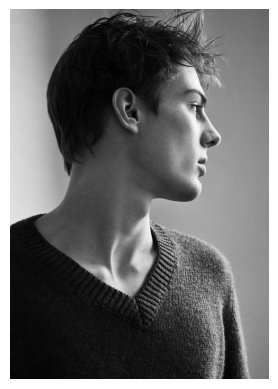

In [6]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(images[0])

plt.imshow(img)
plt.axis("off")
plt.show()

In [7]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten

In [8]:
# Creates a training dataset object by reading images from a specific folder
train_dataset=keras.utils.image_dataset_from_directory(
    # Points to the main directory where your training image subfolders are stored
    directory= data_dir,
    # Automatically uses the names of the subfolders as the class labels
    labels='inferred',
    # Encodes the text labels into integers (e.g., Cat=0, Dog=1)
    label_mode='int',
    # Feeds 32 images at a time to the neural network during training
    batch_size=32,
    # Automatically resizes every image to 256x256 pixels for consistency
    image_size=(256,256),
    validation_split=0.2,
    subset='training',
    seed=123
)

Found 5418 files belonging to 2 classes.
Using 4335 files for training.


In [9]:
# Creates a validation dataset object by reading images from a specific folder
validation_dataset=keras.utils.image_dataset_from_directory(
    # Points to the main directory where your training image subfolders are stored
    directory= data_dir,
    # Automatically uses the names of the subfolders as the class labels
    labels='inferred',
    # Encodes the text labels into integers (e.g., Cat=0, Dog=1)
    label_mode='int',
    # Feeds 32 images at a time to the neural network during training
    batch_size=32,
    # Automatically resizes every image to 256x256 pixels for consistency
    image_size=(256,256),
    validation_split=0.2,
    subset='validation',
    seed=123
)

Found 5418 files belonging to 2 classes.
Using 1083 files for validation.


In [10]:
#normalize
def process(image,label):
  image=tf.cast(image/255,tf.float32)
  return image,label

train_dataset=train_dataset.map(process)
validation_dataset=validation_dataset.map(process)

In [11]:
model=Sequential()
model.add(Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Conv2D(64,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Conv2D(128,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Flatten()) #Converts multi-dimensional feature maps into 1D.Prepares data for fully connected layers
model.add(Dense(128, activation='relu'))
model.add(Dense(128, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
history = model.fit(train_dataset,epochs=10,validation_data=validation_dataset)

Epoch 1/10
136/136 ━━━━━━━━━━━━━━━━━━━━ 102s 669ms/step - accuracy: 0.7271 - loss: 0.5413 - val_accuracy: 0.7331 - val_loss: 0.5282
Epoch 2/10
136/136 ━━━━━━━━━━━━━━━━━━━━ 77s 564ms/step - accuracy: 0.9105 - loss: 0.2245 - val_accuracy: 0.9483 - val_loss: 0.1600
Epoch 3/10
136/136 ━━━━━━━━━━━━━━━━━━━━ 82s 606ms/step - accuracy: 0.9790 - loss: 0.0629 - val_accuracy: 0.9677 - val_loss: 0.0882
Epoch 4/10
136/136 ━━━━━━━━━━━━━━━━━━━━ 77s 569ms/step - accuracy: 0.9947 - loss: 0.0186 - val_accuracy: 0.9889 - val_loss: 0.0577
Epoch 5/10
136/136 ━━━━━━━━━━━━━━━━━━━━ 83s 608ms/step - accuracy: 0.9963 - loss: 0.0152 - val_accuracy: 0.9880 - val_loss: 0.0381
Epoch 6/10
136/136 ━━━━━━━━━━━━━━━━━━━━ 77s 565ms/step - accuracy: 0.9949 - loss: 0.0164 - val_accuracy: 0.9806 - val_loss: 0.0743
Epoch 7/10
136/136 ━━━━━━━━━━━━━━━━━━━━ 88s 610ms/step - accuracy: 0.9963 - loss: 0.0088 - val_accuracy: 0.9723 - val_loss: 0.1118
Epoch 8/10
136/136 ━━━━━━━━━━━━━━━━━━━━ 81s 597ms/step - accuracy: 0.9806 - loss: 

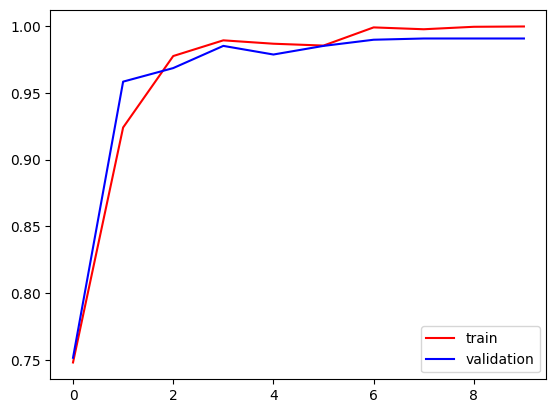

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'],label='train',color='red')
plt.plot(history.history['val_accuracy'],label='validation',color="blue")
plt.legend()
plt.show()

In [ ]:
import cv2

In [ ]:
test_img = cv2.imread("/content/sample_data/beautiful-girl-stands-near-walll-with-leaves.jpg")
test_img = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)

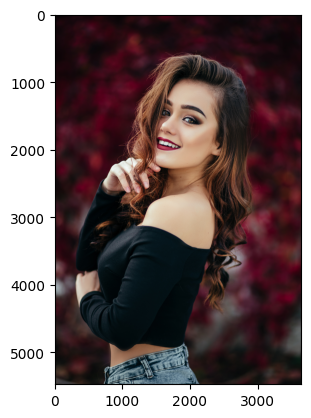

In [ ]:
plt.imshow(test_img)

In [ ]:
test_img.shape

(5472, 3648, 3)

In [ ]:
import numpy as np

test_img = cv2.resize(test_img, (256,256))
# Add a batch dimension and normalize the image
test_input = np.expand_dims(test_img, axis=0) / 255.0

In [ ]:
model.predict(test_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


array([[6.594703e-05]], dtype=float32)

In [ ]:
prediction = model.predict(test_input)

# Apply a threshold (e.g., 0.5) to get a binary classification
predicted_class = 1 if prediction[0][0] > 0.5 else 0

print(f"Raw prediction: {prediction[0][0]:.4f}")
print(f"Predicted class (0 for FEMALE, 1 for MALE): {predicted_class}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Raw prediction: 0.0001
Predicted class (0 for FEMALE, 1 for MALE): 0
